# Which motor features carry the tremor association? MDS-UPDRS subscores and their combinations

`2.32` found that the composite tremor score OFF medication correlates with each participant's medication
effect on prior use (Spearman rho = 0.57, n = 20). The composite averages rest tremor, postural and kinetic
tremor and patient-reported tremor. This notebook asks which of those carries the association, and whether
any combination of motor features does better.

**Pre-specified subscores.** Standard clinical groupings of the OFF-session MDS-UPDRS items, fixed before
looking at their correlations. Each is the mean of its items.

| Subscore | Items |
|---|---|
| Rest tremor | 3.17a-e amplitude, 3.18 constancy |
| Action tremor | 3.15a-b postural, 3.16a-b kinetic |
| Reported tremor | 2.10 (patient-reported, Part II) |
| Rigidity | 3.3a-e |
| Limb bradykinesia | 3.4-3.8, both sides |
| Gait and balance (PIGD) | 2.12, 2.13, 3.10-3.12 |
| Other axial | 3.9 arising, 3.13 posture, 3.14 global spontaneity |
| Bulbar | 3.1 speech, 3.2 facial expression |
| Asymmetry | abs(right - left) / (right + left), summed over all lateralised items |

The project's composites, for reference: tremor score = rest + action + reported tremor items; bradykinesia
score = rigidity + limb bradykinesia + 3.14; PIGD as above.

**Inference without a train / test split.** With 20 participants every patient is used in every test.
Searching many features or combinations inflates the best correlation, so each search is tested against
the same search run on permuted outcomes (a max-statistic permutation test). The family-wise p-value for
the best result is the proportion of permutations whose best correlation is at least as large. Combinations
built without the outcome (principal components) need no such correction beyond the number of components
tested.

**Outcome.** The participant medication effect from `2.26`, as in `2.32`. The 90%-screen refit from `2.33`
is used as a robustness check.

Outputs go to the gitignored `outputs/` directory.

| File | Contents |
|---|---|
| `medication_response_subscores.csv` | each subscore: rho, bootstrap CI, uncorrected and family-wise p, within-subtype rho, 90% screen |
| `medication_response_pca.csv` | outcome-blind principal components: loadings and correlations |
| `medication_response_combinations.csv` | best single and paired composites with family-wise p |
| `medication_response_responsiveness.csv` | levodopa response by motor domain |
| `medication_response_subscore_moderators.csv` | hierarchical moderator models for rest and action tremor |
| `medication_response_text.md` | Results, Methods and Discussion text for the manuscript |
| `medication_response_subscores.pdf/.png` | figure |

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *
import itertools
import re
from statsmodels.stats.multitest import multipletests

from src.data_io import catalog
from src.utils.mcmc_cache import FIT_SETTINGS, TERMS, build_design, ess_bulk, prepare_trials, rhat

In [2]:
metadata = catalog.load_metadata()
trials = catalog.load_trials()
effects = catalog.load("participant_medication_effects").set_index("participant_id")
effects_90 = catalog.read(catalog.output_path("medication_response_accu90_effects.csv")).set_index("participant_id")["effect_90"]

ids = effects.index
off = metadata[metadata["treatment"] == "OFF"].set_index("subject_id").loc[ids]
on = metadata[metadata["treatment"] == "ON"].set_index("subject_id").loc[ids]
y = effects["mean"]
subtype = effects["subtype"]

SUBTYPE_COLOR = {"tremor": "#2a78d6", "bradykinetic": "#eb6834"}   # reference palette slots 1-2
SUBTYPE_LABEL = {"tremor": "Tremor dominant", "bradykinetic": "Bradykinesia dominant"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
COL_MED = TERMS.index("col:med")
rng = np.random.default_rng(0)

## Subscores

Item means, ignoring missing items (five OFF item values are missing across the 20 patients). Items 3.11
freezing of gait, 3.12 postural stability and 3.17e lip / jaw tremor are zero for every patient, so they add
nothing. These are mildly affected patients, and several items barely vary.

In [3]:
SUBSCORES = {
    "Rest tremor": ["317a_Rest_Tremor_Amplitude_RUE", "317b_Rest_Tremor_Amplitude_LUE", "317c_Rest_Tremor_Amplitude_RLE",
                    "317d_Rest_Tremor_Amplitude_LLE", "317e_Rest_Tremor_Amplitude_Lip_Jaw", "318_Constancy_of_Rest_Tremor"],
    "Action tremor": ["315a_Postural_Tremor_RUE", "315b_Postural_Tremor_LUE", "316a_Kinetic_Tremor_RUE", "316b_Kinetic_Tremor_LUE"],
    "Reported tremor": ["210_Tremor"],
    "Rigidity": ["303a_Rigidity_Neck", "303b_Rigidity_RUE", "303c_Rigidity_LUE", "303d_Rigidity_RLE", "303e_Rigidity_LLE"],
    "Limb bradykinesia": ["304a_Finger_Tapping_RUE", "304b_Finger_Tapping_LUE", "305a_Hand_Movements_RUE", "305b_Hand_Movements_LUE",
                          "306a_Pronation_Supination_Movements_RUE", "306b_Pronation_Supination_Movements_LUE",
                          "307a_Toe_Tapping_RLE", "307b_Toe_Tapping_LLE", "308a_Leg_Agility_RLE", "308b_Leg_Agility_LLE"],
    "Gait and balance (PIGD)": ["212_Balance", "213_Freezing", "310_Gait", "311_Freezing_of_Gait", "312_Postural_Stability"],
    "Other axial": ["309_Arising_from_Chair", "313_Posture", "314_Global_Spontaneity_of_Movement"],
    "Bulbar": ["301_Speech", "302_Facial_Expression"],
}


def lateral_pairs(columns):
    """Right / left item pairs, matched on item number and name (3.3b RUE pairs with 3.3c LUE)."""
    key = lambda c: re.sub(r"^(\d+)[a-e]_", r"\1_", c).replace("_R", "_X").replace("_L", "_X")
    lefts = {key(c): c for c in columns if c[0].isdigit() and c.endswith(("LUE", "LLE"))}
    return [(c, lefts[key(c)]) for c in columns if c[0].isdigit() and c.endswith(("RUE", "RLE"))]


subscores = pd.DataFrame({name: off[items].mean(axis=1) for name, items in SUBSCORES.items()})
pairs = lateral_pairs(off.columns)
right, left = off[[r for r, _ in pairs]].sum(axis=1), off[[l for _, l in pairs]].sum(axis=1)
subscores["Asymmetry"] = (right - left).abs() / (right + left)
assert subscores.notna().all().all()
print(f"{len(pairs)} lateralised item pairs; constant items:",
      [c for items in SUBSCORES.values() for c in items if off[c].nunique(dropna=True) <= 1])
reference = pd.DataFrame({"Tremor score (composite)": off["tremor_score"], "Bradykinesia score (composite)": off["bradykinesia_score"],
                          "UPDRS III total": off["UPDRS"]})
subscores.round(2).join(subtype)

11 lateralised item pairs; constant items: ['317e_Rest_Tremor_Amplitude_Lip_Jaw', '311_Freezing_of_Gait', '312_Postural_Stability']


,Rest tremor,Action tremor,Reported tremor,Rigidity,Limb bradykinesia,Gait and balance (PIGD),Other axial,Bulbar,Asymmetry,subtype
participant_id,,,,,,,,,,
P11,1.20,0.75,1.0,1.2,0.6,0.2,0.00,0.5,0.26,tremor
P12,1.00,1.00,2.0,0.4,0.3,0.2,0.00,0.5,1.00,tremor
P17,0.33,1.25,2.0,0.4,1.0,0.4,0.33,1.0,0.44,tremor
P18,0.00,1.25,1.0,0.8,0.3,0.8,0.67,1.0,0.50,tremor
P19,0.83,0.25,1.0,1.0,0.5,0.2,0.00,0.5,0.64,tremor
P29,0.83,1.25,3.0,0.8,1.4,1.4,0.00,1.0,0.36,tremor
P31,0.83,0.50,1.0,0.4,0.0,0.2,0.00,1.0,0.14,tremor
P32,1.00,0.75,4.0,0.8,0.7,0.6,0.33,1.0,0.88,tremor
P6,0.67,1.25,1.0,1.4,0.7,0.4,0.00,0.5,0.58,tremor


## 1. Which component carries the association?

For each subscore: Spearman rho with the medication effect, a bootstrap 95% interval over participants,
the uncorrected permutation p, and the **family-wise** p from the max-statistic permutation over all nine
subscores. Also rho within each subtype, and rho with the 90%-screen effects from `2.33` (16 patients).

In [4]:
def standardised_ranks(X):
    R = np.vstack([stats.rankdata(x) for x in X])
    return (R - R.mean(axis=1, keepdims=True)) / R.std(axis=1, keepdims=True)


def max_stat_test(X, outcome, n_perm=20000):
    """Spearman rho of each row of X with the outcome, uncorrected and max-statistic family-wise p."""
    Rx = standardised_ranks(X)
    ry = stats.rankdata(outcome)
    rho_of = lambda r: Rx @ ((r - r.mean()) / r.std()) / len(r)
    observed = rho_of(ry)
    null = np.array([rho_of(rng.permutation(ry)) for _ in range(n_perm)])
    uncorrected = (np.abs(null) >= np.abs(observed) - 1e-12).mean(axis=0)
    family_wise = (np.abs(null).max(axis=1)[:, None] >= np.abs(observed)[None, :] - 1e-12).mean(axis=0)
    return observed, uncorrected, family_wise


def bootstrap_rho(x, outcome, n_boot=10000):
    x, outcome = np.asarray(x), np.asarray(outcome)
    boot = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x))
        if np.ptp(x[i]) > 0 and np.ptp(outcome[i]) > 0:
            boot.append(stats.spearmanr(x[i], outcome[i])[0])
    return np.percentile(boot, [2.5, 97.5])


rho, p_unc, p_fwe = max_stat_test(subscores.T.to_numpy(), y.to_numpy())
kept_90 = effects_90.index
rows = []
for k, name in enumerate(subscores.columns):
    low, high = bootstrap_rho(subscores[name], y)
    rows.append({"subscore": name, "rho": rho[k], "2.5%": low, "97.5%": high, "p (uncorrected)": p_unc[k], "p (family-wise, 9)": p_fwe[k],
                 **{f"rho within {s}": stats.spearmanr(subscores.loc[g.index, name], y[g.index])[0] for s, g in effects.groupby("subtype")},
                 "rho, 90% screen (n = 16)": stats.spearmanr(subscores.loc[kept_90, name], effects_90)[0],
                 "p, 90% screen": stats.spearmanr(subscores.loc[kept_90, name], effects_90)[1]})
for name in reference:
    low, high = bootstrap_rho(reference[name], y)
    r, p = stats.spearmanr(reference[name], y)
    rows.append({"subscore": name, "rho": r, "2.5%": low, "97.5%": high, "p (uncorrected)": p, "p (family-wise, 9)": np.nan,
                 **{f"rho within {s}": stats.spearmanr(reference.loc[g.index, name], y[g.index])[0] for s, g in effects.groupby("subtype")},
                 "rho, 90% screen (n = 16)": stats.spearmanr(reference.loc[kept_90, name], effects_90)[0],
                 "p, 90% screen": stats.spearmanr(reference.loc[kept_90, name], effects_90)[1]})
subscore_table = pd.DataFrame(rows).set_index("subscore")
subscore_table.round(3)

,rho,2.5%,97.5%,p (uncorrected),"p (family-wise, 9)",rho within bradykinetic,rho within tremor,"rho, 90% screen (n = 16)","p, 90% screen"
subscore,,,,,,,,,
Rest tremor,0.318,-0.105,0.669,0.176,0.786,0.239,-0.107,0.415,0.110
Action tremor,0.574,0.114,0.852,0.010,0.079,0.371,0.699,0.580,0.018
Reported tremor,0.343,-0.086,0.682,0.139,0.706,0.125,0.507,0.269,0.314
Rigidity,0.285,-0.184,0.688,0.220,0.870,0.379,0.304,0.067,0.805
Limb bradykinesia,0.243,-0.249,0.707,0.302,0.942,0.030,0.762,0.021,0.939
Gait and balance (PIGD),0.385,-0.006,0.680,0.094,0.557,0.405,0.470,0.254,0.343
Other axial,-0.283,-0.691,0.230,0.218,0.873,-0.447,0.045,-0.639,0.008
Bulbar,-0.474,-0.768,-0.026,0.036,0.265,-0.707,-0.035,-0.588,0.017
Asymmetry,0.175,-0.266,0.549,0.455,0.994,-0.195,0.430,0.177,0.513


**Does action tremor carry the association independently of rest tremor?** Partial Spearman correlations
(rank-transform, then partial out the other subscore), and the same controlling for subtype.

In [5]:
def partial_spearman(x, outcome, covariates):
    ranked = pd.DataFrame({"x": stats.rankdata(x), "y": stats.rankdata(outcome)}, index=covariates.index)
    Z = sm.add_constant(covariates.apply(stats.rankdata).to_numpy() if covariates.shape[1] else np.empty((len(x), 0)))
    rx = sm.OLS(ranked["x"].to_numpy(), Z).fit().resid
    ry = sm.OLS(ranked["y"].to_numpy(), Z).fit().resid
    return stats.pearsonr(rx, ry)


td = (subtype == "tremor").astype(float).to_frame("subtype")
partials = []
for name, controls in [("Action tremor", ["Rest tremor"]), ("Rest tremor", ["Action tremor"]),
                       ("Action tremor", ["Reported tremor"]), ("Action tremor", []), ("Rest tremor", [])]:
    cov = subscores[controls]
    r, p = partial_spearman(subscores[name], y, cov)
    r_s, p_s = partial_spearman(subscores[name], y, cov.join(td))
    partials.append({"subscore": name, "controlling for": ", ".join(controls) or "nothing",
                     "partial rho": r, "p": p, "partial rho, + subtype": r_s, "p, + subtype": p_s})
pd.DataFrame(partials).round(3)

,subscore,controlling for,partial rho,p,"partial rho, + subtype","p, + subtype"
0,Action tremor,Rest tremor,0.530,0.016,0.535,0.015
1,Rest tremor,Action tremor,0.191,0.420,0.282,0.228
2,Action tremor,Reported tremor,0.509,0.022,0.447,0.048
3,Action tremor,nothing,0.574,0.008,0.491,0.028
4,Rest tremor,nothing,0.318,0.172,0.147,0.537


saved medication_response_subscores.pdf, medication_response_subscores.png


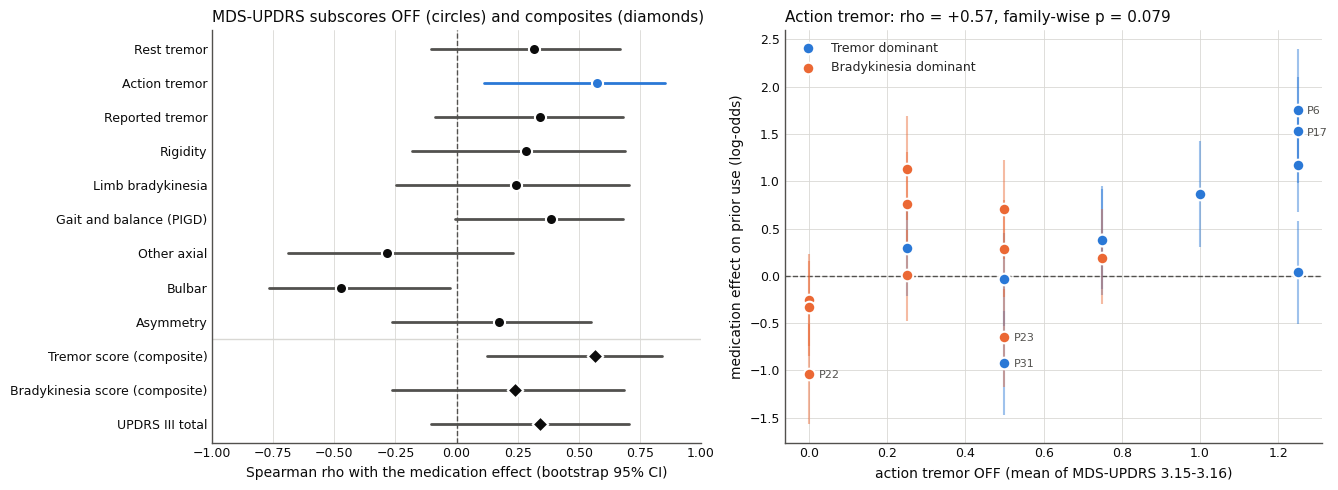

In [6]:
def style(ax):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelcolor=INK, labelsize=9)
    ax.grid(color=GRID, lw=0.6, zorder=0)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
style(ax)
ax.grid(axis="y", visible=False)
order = list(subscores.columns) + list(reference.columns)
for i, name in enumerate(order):
    row = subscore_table.loc[name]
    highlight = name == "Action tremor"
    color = SUBTYPE_COLOR["tremor"] if highlight else MUTED
    ax.plot([row["2.5%"], row["97.5%"]], [i, i], color=color, lw=2, solid_capstyle="round", zorder=2)
    ax.scatter(row["rho"], i, s=64, color=color if highlight else INK, edgecolor="white", linewidth=1.5, zorder=3,
               marker="o" if name in subscores.columns else "D")
ax.axhline(len(subscores.columns) - 0.5, color=GRID, lw=1)
ax.axvline(0, color=MUTED, lw=1, ls="--", zorder=1)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlim(-1, 1)
ax.set_xlabel("Spearman rho with the medication effect (bootstrap 95% CI)", color=INK, fontsize=10)
ax.set_title("MDS-UPDRS subscores OFF (circles) and composites (diamonds)", fontsize=11, color=INK, loc="left")

ax = axes[1]
style(ax)
for s in ["tremor", "bradykinetic"]:
    g = effects[effects["subtype"] == s]
    ax.errorbar(subscores.loc[g.index, "Action tremor"], g["mean"], yerr=[g["mean"] - g["2.5%"], g["97.5%"] - g["mean"]],
                ls="", color=SUBTYPE_COLOR[s], alpha=0.45, lw=1.5, zorder=2)
    ax.scatter(subscores.loc[g.index, "Action tremor"], g["mean"], s=70, color=SUBTYPE_COLOR[s], edgecolor="white",
               linewidth=1.5, zorder=3, label=SUBTYPE_LABEL[s])
ax.axhline(0, color=MUTED, lw=1, ls="--", zorder=1)
for pid in ["P31", "P22", "P23", "P6", "P17"]:
    ax.annotate(pid, (subscores.loc[pid, "Action tremor"], y[pid]), xytext=(7, -3), textcoords="offset points", fontsize=8, color=MUTED)
row = subscore_table.loc["Action tremor"]
ax.set_xlabel("action tremor OFF (mean of MDS-UPDRS 3.15-3.16)", color=INK, fontsize=10)
ax.set_ylabel("medication effect on prior use (log-odds)", color=INK, fontsize=10)
ax.set_title(f"Action tremor: rho = {row['rho']:+.2f}, family-wise p = {row['p (family-wise, 9)']:.3f}", fontsize=11, color=INK, loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
catalog.save_figure(fig, "medication_response_subscores")
plt.show()

## 2. Outcome-blind combinations: principal components

Principal components of the nine standardised subscores, computed without the outcome. The first three
are correlated with the medication effect, Holm-corrected over three.

In [7]:
Z = (subscores - subscores.mean()) / subscores.std(ddof=1)
U, S, Vt = np.linalg.svd(Z.to_numpy(), full_matrices=False)
explained = S ** 2 / (S ** 2).sum()
scores = pd.DataFrame(U[:, :3] * S[:3], index=Z.index, columns=["PC1", "PC2", "PC3"])
loadings = pd.DataFrame(Vt[:3].T, index=Z.columns, columns=["PC1", "PC2", "PC3"])
pc_rows = []
for k, pc in enumerate(scores.columns):
    r, p = stats.spearmanr(scores[pc], y)
    pc_rows.append({"component": pc, "variance explained": explained[k], "rho": r, "p": p})
pcs = pd.DataFrame(pc_rows).set_index("component")
pcs["Holm p"] = multipletests(pcs["p"], method="holm")[1]
display(pcs.round(3))
loadings.round(2)

,variance explained,rho,p,Holm p
component,,,,
PC1,0.288,-0.236,0.316,0.513
PC2,0.230,-0.636,0.003,0.008
PC3,0.164,-0.266,0.257,0.513


,PC1,PC2,PC3
Rest tremor,-0.36,-0.27,0.43
Action tremor,-0.18,-0.46,-0.23
Reported tremor,-0.19,-0.44,-0.21
Rigidity,0.19,-0.43,0.37
Limb bradykinesia,0.41,-0.39,-0.00
Gait and balance (PIGD),0.12,-0.36,-0.53
Other axial,0.56,0.03,-0.04
Bulbar,0.49,0.09,-0.02
Asymmetry,-0.19,0.21,-0.54


**Is PC2 more than the subtype split?** PC2 is the only component that tracks the effect. Its correlation
within each subtype, controlling for subtype, and with the 90%-screen effects. The sign of a component is
arbitrary; PC2 is flipped so that higher means more severe limb signs.

In [8]:
limb_severity = -scores["PC2"] if loadings.loc["Action tremor", "PC2"] < 0 else scores["PC2"]
r_sub, p_sub = partial_spearman(limb_severity, y, td)
pc2_checks = pd.DataFrame([
    {"sample": "all 20", "rho": stats.spearmanr(limb_severity, y)[0], "p": stats.spearmanr(limb_severity, y)[1]},
    *[{"sample": f"within {s} (n = {len(g)})", "rho": stats.spearmanr(limb_severity[g.index], y[g.index])[0],
       "p": stats.spearmanr(limb_severity[g.index], y[g.index])[1]} for s, g in effects.groupby("subtype")],
    {"sample": "controlling for subtype", "rho": r_sub, "p": p_sub},
    {"sample": "90% screen effects (n = 16)", "rho": stats.spearmanr(limb_severity[kept_90], effects_90)[0],
     "p": stats.spearmanr(limb_severity[kept_90], effects_90)[1]},
]).set_index("sample")
pc2_checks.round(3)

,rho,p
sample,,
all 20,0.636,0.003
within bradykinetic (n = 10),0.430,0.214
within tremor (n = 10),0.733,0.016
controlling for subtype,0.592,0.006
90% screen effects (n = 16),0.500,0.049


## 3. Searched combinations: every subscore and every signed pair

Each of the nine subscores alone, and every pair of standardised subscores added or subtracted
(36 pairs x 2 signs), 81 candidates in all. The best candidates are listed with the uncorrected p a naive
analysis would report and the family-wise p over all 81.

In [9]:
names = list(Z.columns)
candidates = {name: Z[name] for name in names}
for a, b in itertools.combinations(names, 2):
    candidates[f"{a} + {b}"] = Z[a] + Z[b]
    candidates[f"{a} - {b}"] = Z[a] - Z[b]
X = np.vstack([v.to_numpy() for v in candidates.values()])
rho_c, p_unc_c, p_fwe_c = max_stat_test(X, y.to_numpy())
combinations = pd.DataFrame({"candidate": list(candidates), "rho": rho_c, "p (uncorrected)": p_unc_c,
                             f"p (family-wise, {len(candidates)})": p_fwe_c}).set_index("candidate")
combinations = combinations.reindex(combinations["rho"].abs().sort_values(ascending=False).index)
best = combinations.index[0]
print(f"best of {len(candidates)}: {best}, rho = {combinations.loc[best, 'rho']:+.3f}")
print(f"its rho with the 90%-screen effects: {stats.spearmanr(candidates[best].loc[kept_90], effects_90)[0]:+.3f}")
combinations.head(10).round(3)

best of 81: Action tremor - Bulbar, rho = +0.685
its rho with the 90%-screen effects: +0.713


,rho,p (uncorrected),"p (family-wise, 81)"
candidate,,,
Action tremor - Bulbar,0.685,0.001,0.066
Gait and balance (PIGD) - Bulbar,0.673,0.002,0.083
Action tremor + Gait and balance (PIGD),0.641,0.004,0.136
Limb bradykinesia - Bulbar,0.625,0.003,0.169
Action tremor + Rigidity,0.619,0.004,0.181
Rest tremor + Gait and balance (PIGD),0.619,0.004,0.181
Limb bradykinesia - Other axial,0.608,0.005,0.208
Action tremor + Reported tremor,0.605,0.007,0.215
Reported tremor - Bulbar,0.592,0.008,0.252


## 4. Levodopa response by motor domain

OFF minus ON for each domain that was scored in both sessions (Part II items were only collected OFF).
A larger value means the domain improved more on medication.

In [10]:
response = pd.DataFrame({name: off[items].mean(axis=1) - on[items].mean(axis=1)
                         for name, items in SUBSCORES.items() if not any(i.startswith("2") for i in items)})
response["Gait and balance (3.10-3.12)"] = off[["310_Gait", "311_Freezing_of_Gait", "312_Postural_Stability"]].mean(axis=1) - \
                                           on[["310_Gait", "311_Freezing_of_Gait", "312_Postural_Stability"]].mean(axis=1)
response["UPDRS III total"] = off["UPDRS"] - on["UPDRS"]
ok = response.notna().all(axis=1)
rho_r, p_unc_r, p_fwe_r = max_stat_test(response[ok].T.to_numpy(), y[ok].to_numpy())
responsiveness = pd.DataFrame({"n": ok.sum(), "rho": rho_r, "p (uncorrected)": p_unc_r, "p (family-wise)": p_fwe_r},
                              index=response.columns)
responsiveness.round(3)

,n,rho,p (uncorrected),p (family-wise)
Rest tremor,20,-0.085,0.721,1.000
Action tremor,20,0.132,0.576,0.997
Rigidity,20,0.111,0.631,0.999
Limb bradykinesia,20,-0.267,0.256,0.869
Other axial,20,-0.143,0.539,0.995
Bulbar,20,-0.419,0.064,0.382
Gait and balance (3.10-3.12),20,0.010,1.000,1.000
UPDRS III total,20,-0.148,0.534,0.995


## 5. Hierarchical moderator models: action versus rest tremor

As in `2.32`: the reported model fitted to the 20 patients together, with standardised subscores entered
with their colour, medication and colour x medication interactions. Action and rest tremor are fitted
alone and together. Cached under `outputs/medication_response_subscore_moderators/`.

In [11]:
def standardised(names):
    return {n: ((subscores[n] - subscores[n].mean()) / subscores[n].std(ddof=1)).to_dict() for n in names}


def signature(names):
    return {n: {k: round(v, 6) for k, v in values.items()} for n, values in standardised(names).items()}


def fit_moderators(names, subset):
    import pymc as pm

    design, outcomes, subject_index, subjects = build_design(subset)
    col, med = subset["col"].to_numpy(), subset["med"].to_numpy()
    columns, terms = [], []
    for n, values in standardised(names).items():
        s = subset["subject_id"].map(values).to_numpy()
        columns += [s, s * col, s * med, s * col * med]
        terms += [n, f"{n}:col", f"{n}:med", f"{n}:col:med"]
    with pm.Model():
        beta = pm.Normal("beta", 0, 2.5, shape=design.shape[1])
        gamma = pm.Normal("gamma", 0, 2.5, shape=len(columns)) if columns else None
        sd_u = pm.HalfNormal("sd_u", 1.0, shape=design.shape[1])
        z_u = pm.Normal("z_u", 0, 1, shape=(len(subjects), design.shape[1]))
        eta = pm.math.sum(design * (beta + (z_u * sd_u)[subject_index]), axis=1)
        if columns:
            eta = eta + pm.math.dot(np.column_stack(columns), gamma)
        pm.Bernoulli("obs", logit_p=eta, observed=outcomes)
        idata = pm.sample(FIT_SETTINGS["draws"], tune=FIT_SETTINGS["tune"], chains=FIT_SETTINGS["chains"],
                          cores=FIT_SETTINGS["chains"], target_accept=FIT_SETTINGS["target_accept"],
                          random_seed=FIT_SETTINGS["seed"], progressbar=False)
    b, sd = idata.posterior["beta"].values, idata.posterior["sd_u"].values
    out = {"fit": " + ".join(names) or "none", "settings": FIT_SETTINGS, "scores": signature(names),
           "sd_u col:med": float(sd[..., COL_MED].mean()), "divergences": int(idata.sample_stats["diverging"].values.sum()),
           "max r_hat (beta)": float(max(rhat(b[..., i]) for i in range(b.shape[-1])))}
    if columns:
        g = idata.posterior["gamma"].values
        for n in names:
            d = g[..., terms.index(f"{n}:col:med")]
            out[n] = {"mean": float(d.mean()), "2.5%": float(np.percentile(d, 2.5)), "97.5%": float(np.percentile(d, 97.5)),
                      "P(> 0)": float((d > 0).mean()), "r_hat": float(rhat(d)), "ess_bulk": float(ess_bulk(d))}
    return out


subset = prepare_trials(trials, list(ids))
fits = {}
for spec in [[], ["Action tremor"], ["Rest tremor"], ["Action tremor", "Rest tremor"]]:
    label = " + ".join(spec) or "none"
    file = catalog.output_path(f"medication_response_subscore_moderators/{label.replace(' ', '_')}.json")
    cached = catalog.read(file) if file.exists() else None
    if cached and cached["settings"] == FIT_SETTINGS and cached["scores"] == signature(spec):
        fits[label] = cached
        continue
    print(f"{label}: sampling")
    fits[label] = fit_moderators(spec, subset)
    catalog.write(fits[label], file)

reference_sd = fits["none"]["sd_u col:med"]
subscore_moderators = pd.DataFrame([
    {"fit": label, "moderator": n, **{k: fit[n][k] for k in ["mean", "2.5%", "97.5%", "P(> 0)", "r_hat", "ess_bulk"]},
     "sd_u col:med": fit["sd_u col:med"], "heterogeneity explained": 1 - (fit["sd_u col:med"] / reference_sd) ** 2,
     "divergences": fit["divergences"]}
    for label, fit in fits.items() for n in ([] if label == "none" else label.split(" + "))
])
print(f"no moderator: between-participant SD {reference_sd:.3f}, divergences {fits['none']['divergences']}")
subscore_moderators.round(3)

no moderator: between-participant SD 0.829, divergences 0


,fit,moderator,mean,2.5%,97.5%,P(> 0),r_hat,ess_bulk,sd_u col:med,heterogeneity explained,divergences
0,Action tremor,Action tremor,0.488,0.145,0.824,0.996,1.001,1902.767,0.687,0.312,0
1,Rest tremor,Rest tremor,0.189,-0.203,0.592,0.832,1.000,1589.563,0.841,-0.029,0
2,Action tremor + Rest tremor,Action tremor,0.472,0.109,0.831,0.994,1.003,1947.829,0.706,0.274,0
3,Action tremor + Rest tremor,Rest tremor,0.067,-0.287,0.432,0.646,1.004,1780.422,0.706,0.274,0


## Results and interpretation

Values are from this run. Permutation p-values move in the third decimal between runs; the fits are cached.

### Short answer

The tremor association is carried by **action tremor** (postural and kinetic, items 3.15-3.16), not by rest
tremor. Action tremor holds within the tremor-dominant group, after controlling for rest tremor and subtype,
and in the hierarchical model, where it explains about 31% of the between-participant spread. Because it was
found by decomposing the tremor score after the fact, its correction for picking the best of nine subscores
leaves it just short of significance (family-wise p = 0.079). No searched combination of motor features beats
chance once the search is accounted for.

### Subscores

| Subscore, OFF | rho [95% CI] | p | family-wise p (9) | within TD | within BD | 90% screen |
|---|---|---|---|---|---|---|
| Action tremor | +0.57 [0.11, 0.85] | 0.010 | 0.079 | +0.70 | +0.37 | +0.58 |
| Rest tremor | +0.32 [-0.11, 0.67] | 0.18 | 0.79 | -0.11 | +0.24 | +0.42 |
| Reported tremor | +0.34 | 0.14 | 0.71 | +0.51 | +0.13 | +0.27 |
| Gait and balance | +0.39 | 0.09 | 0.56 | +0.47 | +0.41 | +0.25 |
| Bulbar | -0.47 [-0.77, -0.03] | 0.036 | 0.27 | -0.04 | -0.71 | -0.59 |
| Rigidity, limb bradykinesia, other axial, asymmetry | \|rho\| at most 0.29 | 0.22 or more | 0.56 or more | | | |

- **Action, not rest, tremor.** Controlling for rest tremor and subtype, action tremor keeps a partial
  rho of +0.54 (p = 0.015); rest tremor controlling for action tremor drops to +0.19. In the hierarchical
  model action tremor moderates col:med by +0.49 per SD [0.15, 0.82] and lowers the between-participant SD
  from 0.83 to 0.69. With both in the model, action tremor stays at +0.47 [0.11, 0.83] and rest tremor
  falls to +0.07 [-0.29, 0.43].
- **The composite tremor score is a diluted version of action tremor.** Same overall rho (0.57), but its
  rest-tremor half adds nothing, which is why it weakened within subtypes in `2.32` and `2.33`.
- **Bulbar signs point the other way** (speech, facial expression), mostly within BD-PD. It does not survive
  correction and is not interpreted further.

### Outcome-blind combination

The second principal component of the nine subscores (23% of their variance) loads on limb tremor,
rigidity, limb bradykinesia and gait, and not on bulbar or other axial items. Flipped so that higher means
more severe limb signs, it correlates +0.64 with the medication effect (Holm p = 0.008 across three
components). It holds controlling for subtype (+0.59, p = 0.006), within TD-PD (+0.73) and at the 90%
screen (+0.50, p = 0.049). Because it was built without the outcome, this is the most defensible
"combination" result. Components estimated from 20 patients are unstable, so the weights should not be
taken as transferable.

### Searched combinations

The best of 81 candidates (each subscore alone, and every signed pair) is action tremor minus bulbar,
rho = +0.69. A naive analysis would report p = 0.001; corrected for the search, p = 0.066. None of the
others comes closer. Combinations do not beat action tremor alone by more than the search itself would.

### Levodopa response

The motor improvement on medication, in any domain or in total, is unrelated to the effect on prior use
(all family-wise p of 0.38 or more). Patients whose prior use rises on medication are not the ones whose
motor signs improve most.

### Caveats

Action tremor takes only six distinct values in these patients, so it is a coarse ordinal score. The
patients are mildly affected, and several items barely vary. The decomposition and the moderator models
were chosen after `2.32` had found the tremor association; only the composite tremor score and the
tremor-versus-bradykinesia pair were planned.

## Text for the manuscript

Results, Methods and Discussion text covering `2.32`-`2.34`, saved to `outputs/medication_response_text.md` by the cell below. Update its numbers if any of those notebooks is rerun on new data.

In [12]:
MANUSCRIPT_TEXT = r"""
# Individual differences in the medication effect on prior use: text for the manuscript

Numbers come from `2.26` and `2.32`-`2.34`. Placeholders in square brackets need filling: figure and table
numbers, and citations for the Discussion. Spelling follows the rest of the manuscript.

## Methods: participant-level analyses

Participant-level medication effects were the posterior means of $eta_{	ext{col:med}} + u_{i,	ext{col:med}}$
from the hierarchical model (4,000 posterior draws per participant). We related them to clinical,
pharmacological, motor and behavioural characteristics measured in the OFF-medication session, so that no
predictor was measured under the treatment whose effect it was meant to predict. Associations were assessed
with Spearman correlations, percentile bootstrap 95% confidence intervals (10,000 resamples of
participants) and two-sided permutation p-values (20,000 permutations). Multiplicity was controlled with the
Benjamini-Hochberg procedure within predefined families of measures, or with Holm correction for planned
comparisons. Where the strongest of several candidate measures is reported, its significance was assessed
against the permutation distribution of the maximum absolute correlation across all candidates, which
controls the family-wise error rate of the search. Dependence of the medication effect on OFF-state prior use
was tested by correlating the OFF-to-ON change with the mean of the two sessions (Oldham's method), which
removes the regression-to-the-mean artefact of correlating a change with its own baseline.

MDS-UPDRS Part III subscores were item means in the OFF session: rest tremor (3.17a-e, 3.18), action tremor
(postural 3.15a-b and kinetic 3.16a-b), patient-reported tremor (2.10), rigidity (3.3a-e), limb
bradykinesia (3.4-3.8), gait and balance (2.12, 2.13, 3.10-3.12), other axial signs (3.9, 3.13, 3.14) and
bulbar signs (3.1, 3.2), with lateral asymmetry computed as |R - L| / (R + L) over all lateralised items.
To test whether a characteristic moderated the medication effect while accounting for trial-level
uncertainty, its standardised value and its interactions with colour, medication and colour x medication
were added to the hierarchical model, which was sampled with the same priors and settings as the main
analysis.

## Results

**Participants differed in how medication changed their use of the prior.** Participant-level effects
varied widely in both subtypes (between-participant SD 0.91 [0.53, 1.49] log-odds in TD-PD and 0.79
[0.45, 1.32] in BD-PD; Fig. [5a]).

**The medication effect did not depend on OFF-state prior use.** Patients with weaker prior use OFF
medication showed larger increases ON (r = -0.78). However, a patient's prior use OFF and ON were
uncorrelated (r = -0.16, n = 20; r = -0.13 across all 40 patients), although prior use was reliable within
a session (split-half reliability 0.85). Correlated with the mean of the two sessions, the change showed no
baseline dependence (r = -0.05, p = 0.83). In the hierarchical model, the correlation between participants'
mean prior use and their medication effect was -0.15 [-0.47, 0.18] in TD-PD and -0.10 [-0.43, 0.24] in
BD-PD. The apparent baseline dependence is therefore attributable to regression to the mean.

**Clinical and pharmacological characteristics did not predict the medication effect.** The effect was not
associated with age, sex, disease duration, MoCA score, Hoehn & Yahr stage, duration of the OFF washout,
levodopa formulation, or the motor response to levodopa (all |rho| <= 0.34, p >= 0.14; Supplementary
Table [S#]). Levodopa-equivalent daily dose could be derived for only 7 patients (rho = 0.41, p = 0.36). Of
the OFF-state task measures, psychometric sensitivity, reward- and choice-history weights, lapse rate,
easy-trial accuracy and the drift-diffusion boundary separation, non-decision time and drift gain were
unrelated to the effect. Median response time OFF correlated negatively (rho = -0.47, p = 0.040), but it was
itself correlated with OFF-state prior use (rho = 0.61) and did not survive correction (q = 0.52).

**Tremor severity, specifically action tremor, was associated with a larger medication effect.** Tremor
severity OFF medication correlated with the medication effect (rho = 0.57, 95% CI [0.12, 0.84], p = 0.009;
Holm-corrected across the tremor and bradykinesia scores, p = 0.019), with the same sign within each subtype
(TD-PD rho = 0.59; BD-PD rho = 0.45), whereas bradykinesia severity was not (rho = 0.24, p = 0.31). The
association was unchanged when the analysis was restricted to the 16 patients with at least 90% accuracy on
easy trials in both sessions (rho = 0.59, p = 0.019). Entered as a moderator in the hierarchical model,
tremor severity increased the medication effect by 0.39 log-odds per standard deviation (95% CrI [0.03,
0.76]). In an exploratory decomposition of the tremor score, the association was carried by action tremor
(rho = 0.57 [0.11, 0.85], p = 0.010) rather than rest tremor (rho = 0.32, p = 0.18). Action tremor remained
associated after controlling for rest tremor and subtype (partial rho = 0.54, p = 0.015) and in the
hierarchical model (0.49 log-odds per SD [0.15, 0.82]; with rest tremor in the same model, 0.47 [0.11, 0.83]
against 0.07 [-0.29, 0.43] for rest tremor), where it accounted for approximately 31% of the
between-participant variance in the medication effect. Corrected for selecting the strongest of nine
subscores, the action-tremor association fell just short of significance (family-wise p = 0.079). An
outcome-blind composite, the second principal component of the nine subscores, which loaded on limb tremor,
rigidity, bradykinesia and gait but not on bulbar or axial signs, also correlated with the medication effect
(rho = 0.64, Holm-corrected p = 0.008 across three components; controlling for subtype, rho = 0.59,
p = 0.006). No pairwise combination of subscores exceeded chance once the search was accounted for (best
rho = 0.69, family-wise p = 0.066 across 81 candidates), and the motor improvement on medication, in any
domain, was unrelated to the medication effect on prior use (all family-wise p >= 0.38).

## Discussion

The effect of dopaminergic medication on the use of prior information varied substantially between
patients. This variation was not explained by demographic or cognitive factors, dose, washout, or the size
of the motor response to medication, and it did not depend on how strongly a patient used the prior when OFF
medication. It was associated with the severity of tremor, and in an exploratory analysis specifically with
action (postural and kinetic) tremor rather than rest tremor. This extends the group difference between
tremor- and bradykinesia-dominant patients into a graded relationship that cuts across the subtype boundary.
One possibility is that patients with prominent tremor differ in the pattern of striatal dopaminergic
denervation, or in the involvement of the cerebello-thalamo-cortical circuit implicated in parkinsonian
tremor [citations], such that dopamine replacement restores rather than overdoses the circuits that support
the use of prior expectations [citations: dopamine overdose hypothesis]. That the cognitive and motor
responses to medication were unrelated suggests that they are mediated by partly separate circuits.

## Limitations

These analyses are exploratory and rest on 20 patients. Each patient contributed one OFF and one ON
session, so a participant-level effect combines medication with any other difference between the two
visits. Because prior use OFF and ON was uncorrelated, a substantial part of the individual variation is
specific to the visit, and a stable patient characteristic can account for only part of it. The
action-tremor finding emerged from a decomposition of the tremor score and does not survive correction for
that choice, the patients were mildly affected, and the action-tremor score takes few distinct values.
Participant-level estimates should therefore not be used to classify individual patients as responders or
non-responders. The association should be tested in an independent sample; the 19 patients in this study
without item-level MDS-UPDRS ratings would provide one if those ratings can be obtained.
"""
catalog.save_text(MANUSCRIPT_TEXT, "medication_response_text.md")

saved medication_response_text.md


## Save

In [13]:
catalog.save_table(subscore_table, "medication_response_subscores.csv")
catalog.save_table(pd.concat([pcs, loadings.T], axis=1), "medication_response_pca.csv")
catalog.save_table(combinations, "medication_response_combinations.csv")
catalog.save_table(responsiveness, "medication_response_responsiveness.csv")
catalog.save_table(subscore_moderators, "medication_response_subscore_moderators.csv", index=False)

saved medication_response_subscores.csv
saved medication_response_pca.csv
saved medication_response_combinations.csv
saved medication_response_responsiveness.csv
saved medication_response_subscore_moderators.csv
